# 3D pose in Spyglass: DANDI:001935 (Uchida lab)

This notebook reads the Uchida lab's 3D pose data (SFARI ARC, DANDI:001935) back out of a Spyglass database and works with it. Six calibrated cameras film the arena, and DANNCE estimates 23 body keypoints of the implanted rat in 3D from their videos. In the social sessions a second rat without an implant, the partner, shares the arena, and sDANNCE tracks both animals.

The pose tables come from the `ndx-pose-multicamera` branch of the CatalystNeuro Spyglass fork ([catalystneuro/spyglass PR #1](https://github.com/catalystneuro/spyglass/pull/1)), merged into the `uchida-integration` branch used here:

- `ImportedMultiCameraPose`: one row per pose container (`MultiCameraPoseEstimation`) in an NWB file. Lone sessions have the subject's; social sessions also have the partner's. Its `.BodyPart` part has one row per keypoint, and its `.Camera` part links each camera's video (`VideoFile`) to that camera's calibration.
- `CameraCalibration`: one row per session and calibrated camera, pointing to the `CalibratedCamera` in the file.
- `CameraDevice`, `VideoFile`, `TaskEpoch` and `IntervalList`: Spyglass's common tables, filled from the same files.

**Where the data lives**

- **Database (MySQL):** which pose containers, keypoints, cameras and videos each session has, the task condition and the pose's valid time interval.
- **NWB file on disk:** the keypoint coordinates and the calibration matrices. `fetch_pose_dataframe()`, `fetch_skeleton()` and `fetch_calibrations()` open the file registered in `Nwbfile`.
- **Video files (.mp4):** on the lab data share. The NWB file stores their paths, and `fetch_video_paths()` returns them.

Section 1 checks what the database holds using queries alone. Section 2 fetches the coordinates and works with them: one lone session, then the partner in a social session, then every session side by side.

**Running it:** this notebook runs in the `spyglass-uchida-lab-env` conda env inside WSL2, created with `../bootstrap_wsl.sh`. The database is the `spyglass-uchida-db` Docker container on port 3307; see `../docker-compose.yml`, `../dj_local_conf.json` and `../spyglass-ingestion-notes.md`. The video frames in section 2 are read from the data share; set `DATA_SHARE` below to the folder that holds `Uchida-CN-data-share`.

In [1]:
from pathlib import Path

import datajoint as dj

# Load the connection config BEFORE importing spyglass: spyglass declares its schemas
# at import time and would otherwise connect with default settings (including TLS,
# which the local Docker MySQL doesn't use).
dj.config.load(str(Path("..") / "dj_local_conf.json"))
dj.conn(use_tls=False)

[2026-11-10 10:52:23,569][INFO]: DataJoint is configured from /mnt/c/Users/amtra/CatalystNeuro/uchida-lab-to-nwb/spyglass/dj_local_conf.json


[2026-11-10 10:52:23,579][INFO]: DataJoint 0.14.10 connected to root@127.0.0.1:3307


DataJoint connection (connected) root@127.0.0.1:3307

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from spyglass.common import CameraDevice, IntervalList, Session, TaskEpoch, VideoFile
from spyglass.position.v1.imported_multicam_pose import (
    CameraCalibration,
    ImportedMultiCameraPose,
)

# Folder holding `Uchida-CN-data-share` (the H: drive, seen from WSL)
DATA_SHARE = Path("/mnt/h")

pd.set_option("display.max_colwidth", 60)

## 1. What the database holds

Everything in this section comes from database queries; no NWB or video file is opened.

### Pose entries per session

The query below lists every `ImportedMultiCameraPose` row with its session, task condition (from `TaskEpoch`), and the number of `.BodyPart` and `.Camera` rows. `aggr` counts part-table rows per entry; `keep_all_rows=True` keeps an entry with no camera rows.

In [3]:
counts = ImportedMultiCameraPose.aggr(
    ImportedMultiCameraPose.BodyPart, n_body_parts="count(*)"
) * ImportedMultiCameraPose.aggr(
    ImportedMultiCameraPose.Camera, n_cameras="count(*)", keep_all_rows=True
)
pose_entries = (
    pd.DataFrame(
        (Session.proj("subject_id", "session_id") * TaskEpoch.proj("task_name") * counts).fetch(
            "nwb_file_name", "subject_id", "session_id", "task_name", "pose_estimation_name",
            "n_body_parts", "n_cameras", as_dict=True,
        )
    )
    .sort_values(["subject_id", "session_id", "pose_estimation_name"])
    .reset_index(drop=True)
)
RAT_OF = {"PoseEstimationDANNCE": "subject", "PoseEstimationDANNCEPartner": "partner"}
pose_entries["rat"] = pose_entries["pose_estimation_name"].map(RAT_OF)
pose_entries

,nwb_file_name,pose_estimation_name,subject_id,session_id,task_name,n_body_parts,n_cameras,rat
0,sub-M4_ses-day-1-lone_.nwb,PoseEstimationDANNCE,M4,day-1-lone,lone,23,6,subject
1,sub-M4_ses-day-1-social_.nwb,PoseEstimationDANNCE,M4,day-1-social,social,23,6,subject
2,sub-M4_ses-day-1-social_.nwb,PoseEstimationDANNCEPartner,M4,day-1-social,social,23,6,partner
3,sub-M4_ses-day-2-lone_.nwb,PoseEstimationDANNCE,M4,day-2-lone,lone,23,6,subject
4,sub-M4_ses-day-2-social_.nwb,PoseEstimationDANNCE,M4,day-2-social,social,23,6,subject
5,sub-M4_ses-day-2-social_.nwb,PoseEstimationDANNCEPartner,M4,day-2-social,social,23,6,partner
6,sub-M5_ses-day-1-lone_.nwb,PoseEstimationDANNCE,M5,day-1-lone,lone,23,6,subject
7,sub-M5_ses-day-1-social_.nwb,PoseEstimationDANNCE,M5,day-1-social,social,23,6,subject
8,sub-M5_ses-day-1-social_.nwb,PoseEstimationDANNCEPartner,M5,day-1-social,social,23,6,partner
9,sub-M5_ses-day-2-lone_.nwb,PoseEstimationDANNCE,M5,day-2-lone,lone,23,6,subject


Lone sessions have one pose container, the subject's. Social sessions have two: `PoseEstimationDANNCE` for the subject and `PoseEstimationDANNCEPartner` for the partner. Both have the same 23 keypoints.

Each container has six `.Camera` rows, one per camera, except in M7 day-1-social. There, cameras 1, 2 and 4 have no calibration in the NWB file, and `.Camera` only links cameras that have one. Their videos are still in `VideoFile`, as the next table shows.

### Cameras, videos and calibrations

`CameraDevice` is a shared catalog keyed by camera name; all sessions use the same six Basler cameras. Each session then has one `VideoFile` row per camera and one `CameraCalibration` row per calibrated camera.

In [4]:
display(CameraDevice.proj("manufacturer", "model", "camera_id").fetch(format="frame"))

sessions = (
    pose_entries[["nwb_file_name", "subject_id", "session_id", "task_name"]]
    .drop_duplicates()
    .reset_index(drop=True)
)
sessions["n_videos"] = [len(VideoFile & {"nwb_file_name": f}) for f in sessions["nwb_file_name"]]
sessions["n_calibrations"] = [
    len(CameraCalibration & {"nwb_file_name": f}) for f in sessions["nwb_file_name"]
]
sessions

,manufacturer,model,camera_id
camera_name,,,
Camera1,basler,a2A1920-160ucPRO,1
Camera2,basler,a2A1920-160ucPRO,2
Camera3,basler,a2A1920-160ucPRO,3
Camera4,basler,a2A1920-160ucPRO,4
Camera5,basler,a2A1920-160ucPRO,5
Camera6,basler,a2A1920-160ucPRO,6


,nwb_file_name,subject_id,session_id,task_name,n_videos,n_calibrations
0,sub-M4_ses-day-1-lone_.nwb,M4,day-1-lone,lone,6,6
1,sub-M4_ses-day-1-social_.nwb,M4,day-1-social,social,6,6
2,sub-M4_ses-day-2-lone_.nwb,M4,day-2-lone,lone,6,6
3,sub-M4_ses-day-2-social_.nwb,M4,day-2-social,social,6,6
4,sub-M5_ses-day-1-lone_.nwb,M5,day-1-lone,lone,6,6
5,sub-M5_ses-day-1-social_.nwb,M5,day-1-social,social,6,6
6,sub-M5_ses-day-2-lone_.nwb,M5,day-2-lone,lone,6,6
7,sub-M5_ses-day-2-social_.nwb,M5,day-2-social,social,6,6
8,sub-M7_ses-day-1-lone_.nwb,M7,day-1-lone,lone,6,6
9,sub-M7_ses-day-1-social_.nwb,M7,day-1-social,social,6,3


### Valid times

Each pose container's valid times are stored in `IntervalList` as `pose_<container>_valid_intervals`, next to the session's task epoch (`01_lone` or `01_social`). Lone sessions last about 30 minutes and social sessions about 35, except M4 day-1-social, which lasts 30.

In [5]:
def interval_span(nwb_file_name, interval_list_name):
    valid_times = (
        IntervalList
        & {"nwb_file_name": nwb_file_name, "interval_list_name": interval_list_name}
    ).fetch1("valid_times")
    return valid_times[0][0], valid_times[-1][1], len(valid_times)


rows = []
for entry in (ImportedMultiCameraPose * TaskEpoch.proj("task_name", epoch_interval="interval_list_name")).fetch(as_dict=True):
    pose_start, pose_end, n_pose = interval_span(entry["nwb_file_name"], entry["interval_list_name"])
    epoch_start, epoch_end, _ = interval_span(entry["nwb_file_name"], entry["epoch_interval"])
    rows.append(
        {
            "nwb_file_name": entry["nwb_file_name"],
            "rat": RAT_OF[entry["pose_estimation_name"]],
            "epoch_s": (epoch_start, epoch_end),
            "pose_start_s": pose_start,
            "pose_end_s": pose_end,
            "pose_intervals": n_pose,
            "pose_min": (pose_end - pose_start) / 60,
        }
    )
pose_times = pd.DataFrame(rows).sort_values(["nwb_file_name", "rat"], ascending=[True, False]).reset_index(drop=True)
pose_times.round(2)

,nwb_file_name,rat,epoch_s,pose_start_s,pose_end_s,pose_intervals,pose_min
0,sub-M4_ses-day-1-lone_.nwb,subject,"(0.0, 1820.0)",11.23,1811.21,1,30.0
1,sub-M4_ses-day-1-social_.nwb,subject,"(0.0, 1820.0)",11.14,1811.12,1,30.0
2,sub-M4_ses-day-1-social_.nwb,partner,"(0.0, 1820.0)",11.14,1811.12,1,30.0
3,sub-M4_ses-day-2-lone_.nwb,subject,"(0.0, 1820.0)",11.02,1811.00,1,30.0
4,sub-M4_ses-day-2-social_.nwb,subject,"(0.0, 2120.0)",13.68,2113.66,1,35.0
5,sub-M4_ses-day-2-social_.nwb,partner,"(0.0, 2120.0)",13.68,2113.66,1,35.0
6,sub-M5_ses-day-1-lone_.nwb,subject,"(0.0, 1820.0)",13.88,1813.86,1,30.0
7,sub-M5_ses-day-1-social_.nwb,subject,"(0.0, 2120.0)",11.05,2111.03,1,35.0
8,sub-M5_ses-day-1-social_.nwb,partner,"(0.0, 2120.0)",11.05,2111.03,1,35.0
9,sub-M5_ses-day-2-lone_.nwb,subject,"(0.0, 1820.0)",11.08,1811.07,1,30.0


### Completeness checks

The checks below state what every session in this dataset should look like and assert it for each session in the database, using only the query results above. A failure names the session and what's wrong, so the notebook doubles as a test after new sessions are inserted.

In [6]:
EXPECTED_CONTAINERS = {
    "lone": {"PoseEstimationDANNCE"},
    "social": {"PoseEstimationDANNCE", "PoseEstimationDANNCEPartner"},
}
N_BODY_PARTS = 23
N_CAMERAS = 6

assert len(sessions) > 0, "No sessions with pose in the database"

for session in sessions.itertuples():
    name = session.nwb_file_name
    entries = pose_entries[pose_entries["nwb_file_name"] == name]
    times = pose_times[pose_times["nwb_file_name"] == name]

    # Containers: the subject's, plus the partner's in social sessions
    assert set(entries["pose_estimation_name"]) == EXPECTED_CONTAINERS[session.task_name], (
        f"{name}: containers {sorted(entries['pose_estimation_name'])}"
    )
    assert (entries["n_body_parts"] == N_BODY_PARTS).all(), f"{name}: body parts {list(entries['n_body_parts'])}"

    # Cameras: a video per camera; .Camera rows exactly for the calibrated ones
    assert session.n_videos == N_CAMERAS, f"{name}: {session.n_videos} videos"
    assert (entries["n_cameras"] == session.n_calibrations).all(), (
        f"{name}: .Camera rows {list(entries['n_cameras'])}, calibrations {session.n_calibrations}"
    )

    # Times: one continuous pose interval, inside the task epoch
    assert (times["pose_intervals"] == 1).all(), f"{name}: pose interval has gaps"
    for row in times.itertuples():
        assert row.epoch_s[0] <= row.pose_start_s and row.pose_end_s <= row.epoch_s[1], (
            f"{name}: {row.rat} pose {row.pose_start_s:.1f}-{row.pose_end_s:.1f} s outside epoch {row.epoch_s}"
        )

print(f"All completeness checks passed for {len(sessions)} session(s).")
partial = sessions[sessions["n_calibrations"] < N_CAMERAS]
for row in partial.itertuples():
    print(f"  {row.nwb_file_name}: {row.n_calibrations} of {N_CAMERAS} cameras calibrated")

All completeness checks passed for 12 session(s).
  sub-M7_ses-day-1-social_.nwb: 3 of 6 cameras calibrated


## 2. Working with the pose

`fetch_pose_dataframe(key)` returns one container's pose as a DataFrame indexed by time in seconds, with a column group per keypoint (`x`, `y`, `z` in millimeters, plus `likelihood`). For DANNCE, `likelihood` holds the confidence stored in the file: the maximum of DANNCE's 3D probability volume. It is not a probability between 0 and 1. `fetch_skeleton(key)` returns the keypoint names and the edges between them.

The helpers below strip the `PoseEstimationSeries` prefix from the column names and stack the coordinates into a `(frames, keypoints, 3)` array in skeleton order.

Colors in the figures: blue for the subject and orange for the partner.

In [7]:
def fetch_pose(key):
    # One container's pose, columns (keypoint, x/y/z/likelihood); reads the NWB file
    pose = ImportedMultiCameraPose().fetch_pose_dataframe(key)
    return pose.rename(columns=lambda c: c.removeprefix("PoseEstimationSeries"), level=0)


def keypoint_array(pose, nodes):
    # (frames, keypoints, 3) coordinates in mm, keypoints in `nodes` order
    return np.stack([pose[node][["x", "y", "z"]].to_numpy() for node in nodes], axis=1)


RAT_COLORS = {"subject": "#2a78d6", "partner": "#eb6834"}
SURFACE, INK, INK_2, MUTED, GRID, AXIS = (
    "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
)

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": AXIS,
        "axes.labelcolor": INK_2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titlelocation": "left",
        "axes.labelsize": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.frameon": False,
        "legend.fontsize": 9,
        "legend.labelcolor": INK_2,
        "font.family": "sans-serif",
    }
)

### One lone session

The walkthrough uses the first lone session. The figure shows the full skeleton at one frame in 3D.

In [8]:
lone = sessions[sessions["task_name"] == "lone"].iloc[0]
lone_key = {"nwb_file_name": lone["nwb_file_name"], "pose_estimation_name": "PoseEstimationDANNCE"}
lone_label = f"{lone['subject_id']}, {lone['session_id']}"

skeleton = ImportedMultiCameraPose().fetch_skeleton(lone_key)
nodes = skeleton["nodes"]
edges = [(nodes.index(a), nodes.index(b)) for a, b in skeleton["edges"]]

lone_pose = fetch_pose(lone_key)
lone_xyz = keypoint_array(lone_pose, nodes)
print(f"{lone_label}: {lone_xyz.shape[0]} frames, {len(nodes)} keypoints, {len(edges)} edges")
print(f"time {lone_pose.index[0]:.3f}-{lone_pose.index[-1]:.3f} s")
lone_pose[["Snout", "TailBase"]].head()

M4, day-1-lone: 90000 frames, 23 keypoints, 23 edges
time 11.230-1811.210 s


Snout                                      TailBase              \
                x           y          z likelihood           x           y   
time                                                                          
11.23 -228.134689   72.755318  14.130931  27.778425 -167.747192 -152.294067   
11.25 -225.884979   85.370010  14.611329  29.041672 -175.295609 -141.483643   
11.27 -225.019836   95.808144  13.574511  29.449593 -184.640625 -128.722351   
11.29 -220.753220  106.765205  13.769406  29.314281 -198.271057 -115.175583   
11.31 -216.400864  117.983597  16.915455  28.963423 -207.018188 -110.232903   

                             
               z likelihood  
time                         
11.23  66.698265  27.778425  
11.25  74.607338  29.041672  
11.27  71.274956  29.449593  
11.29  62.709351  29.314281  
11.31  50.656395  28.963423

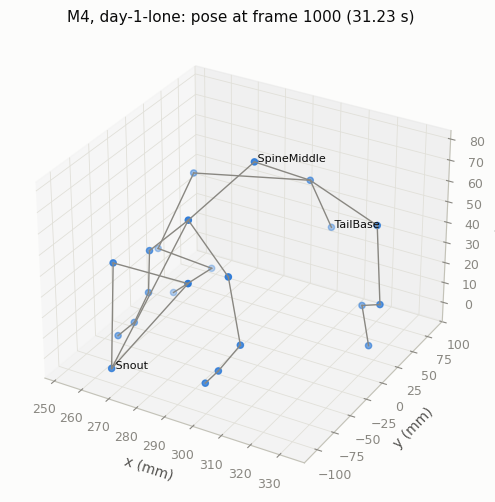

In [9]:
frame_idx = 1000
coords = lone_xyz[frame_idx]

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection="3d")
for i, j in edges:
    ax.plot(*coords[[i, j]].T, color=MUTED, linewidth=1)
ax.scatter(*coords.T, color=RAT_COLORS["subject"], s=20)
for node in ("Snout", "SpineMiddle", "TailBase"):
    ax.text(*coords[nodes.index(node)], f" {node}", fontsize=8, color=INK)
ax.set_xlabel("x (mm)")
ax.set_ylabel("y (mm)")
ax.set_zlabel("z (mm)")
ax.set_title(f"{lone_label}: pose at frame {frame_idx} ({lone_pose.index[frame_idx]:.2f} s)")
plt.show()

### Movement over the session

`SpineMiddle` is a stable point on the body to follow. The left panel shows its path seen from above, colored by time. The right panel shows its speed, from frame-to-frame steps smoothed over 1 s.

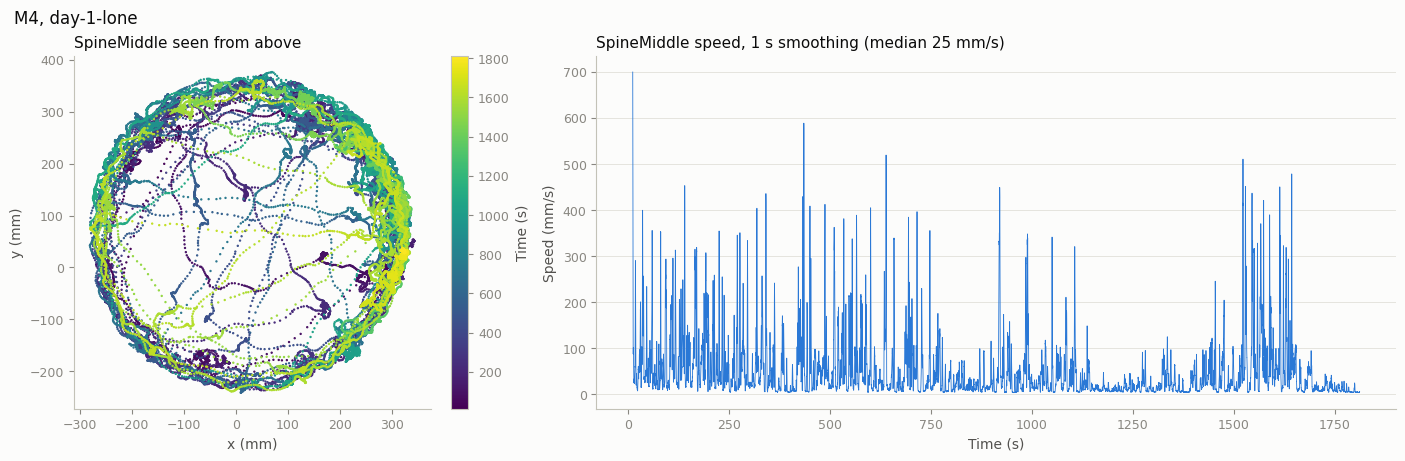

In [10]:
def body_speed(pose, keypoint="SpineMiddle", smooth_s=1.0):
    # Speed of one keypoint in mm/s, smoothed with a centered rolling mean
    xyz = pose[keypoint][["x", "y", "z"]].to_numpy()
    t = pose.index.to_numpy()
    step = np.linalg.norm(np.diff(xyz, axis=0), axis=1) / np.diff(t)
    speed = pd.Series(step, index=t[1:])
    fs = 1.0 / np.median(np.diff(t))
    return speed.rolling(int(smooth_s * fs), center=True, min_periods=1).mean()


spine = lone_pose["SpineMiddle"]
speed = body_speed(lone_pose)

fig, (ax_path, ax_speed) = plt.subplots(
    1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2]}, constrained_layout=True
)
points = ax_path.scatter(spine["x"], spine["y"], c=spine.index, cmap="viridis", s=0.5, rasterized=True)
fig.colorbar(points, ax=ax_path, label="Time (s)")
ax_path.set_aspect("equal")
ax_path.grid(False)
ax_path.set_xlabel("x (mm)")
ax_path.set_ylabel("y (mm)")
ax_path.set_title("SpineMiddle seen from above")

ax_speed.plot(speed.index, speed, color=RAT_COLORS["subject"], linewidth=0.6, rasterized=True)
ax_speed.set_xlabel("Time (s)")
ax_speed.set_ylabel("Speed (mm/s)")
ax_speed.set_title(f"SpineMiddle speed, 1 s smoothing (median {speed.median():.0f} mm/s)")
fig.suptitle(lone_label, x=0.01, ha="left", color=INK)
plt.show()

### Keypoints on the video frames

The `.Camera` part links each camera to its video and calibration. `fetch_video_paths(key)` returns each video's path as written in the NWB file, relative to the folder the file was converted into; `resolve_video` maps it onto `DATA_SHARE`. `fetch_calibrations(key)` returns each camera's intrinsic matrix, rotation, translation and distortion coefficients.

With them, the 3D keypoints can be projected into each camera's pixel coordinates and drawn on the frame they were estimated from. DANNCE stores the matrices in MATLAB's row-vector convention, the transpose of what OpenCV's `cv2.projectPoints` expects, hence the transposes. The pose and the videos have one sample per camera frame, so pose frame `i` is video frame `i`.

In [11]:
def resolve_video(relative_path):
    # Path from fetch_video_paths() mapped onto DATA_SHARE
    parts = [part for part in Path(relative_path).parts if part != ".."]
    return DATA_SHARE.joinpath(*parts)


def project_points(points_3d, calibration):
    # (n, 3) world points in mm -> (n, 2) pixel coordinates of one camera
    rotation_vector, _ = cv2.Rodrigues(np.asarray(calibration["rotation_matrix"]).T)
    points_2d, _ = cv2.projectPoints(
        np.asarray(points_3d, dtype=float),
        rotation_vector,
        np.asarray(calibration["translation_vector"], dtype=float),
        np.asarray(calibration["intrinsic_matrix"]).T,
        np.asarray(calibration["distortion_coefficients"], dtype=float),
    )
    return points_2d.reshape(-1, 2)


def read_frame(video_path, frame_idx):
    capture = cv2.VideoCapture(str(video_path))
    capture.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    success, frame = capture.read()
    capture.release()
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB) if success else None


def draw_pose(ax, points_2d, color, label=None):
    for i, j in edges:
        ax.plot(*points_2d[[i, j]].T, color=color, linewidth=1)
    ax.scatter(*points_2d.T, color=color, s=8, zorder=3, label=label)


video_paths = {cam: resolve_video(p) for cam, p in ImportedMultiCameraPose().fetch_video_paths(lone_key).items()}
calibrations = ImportedMultiCameraPose().fetch_calibrations(lone_key)
missing = [str(p) for p in video_paths.values() if not p.exists()]
print("Videos not found (check DATA_SHARE):" if missing else "All videos found.", *missing, sep="\n  ")

All videos found.


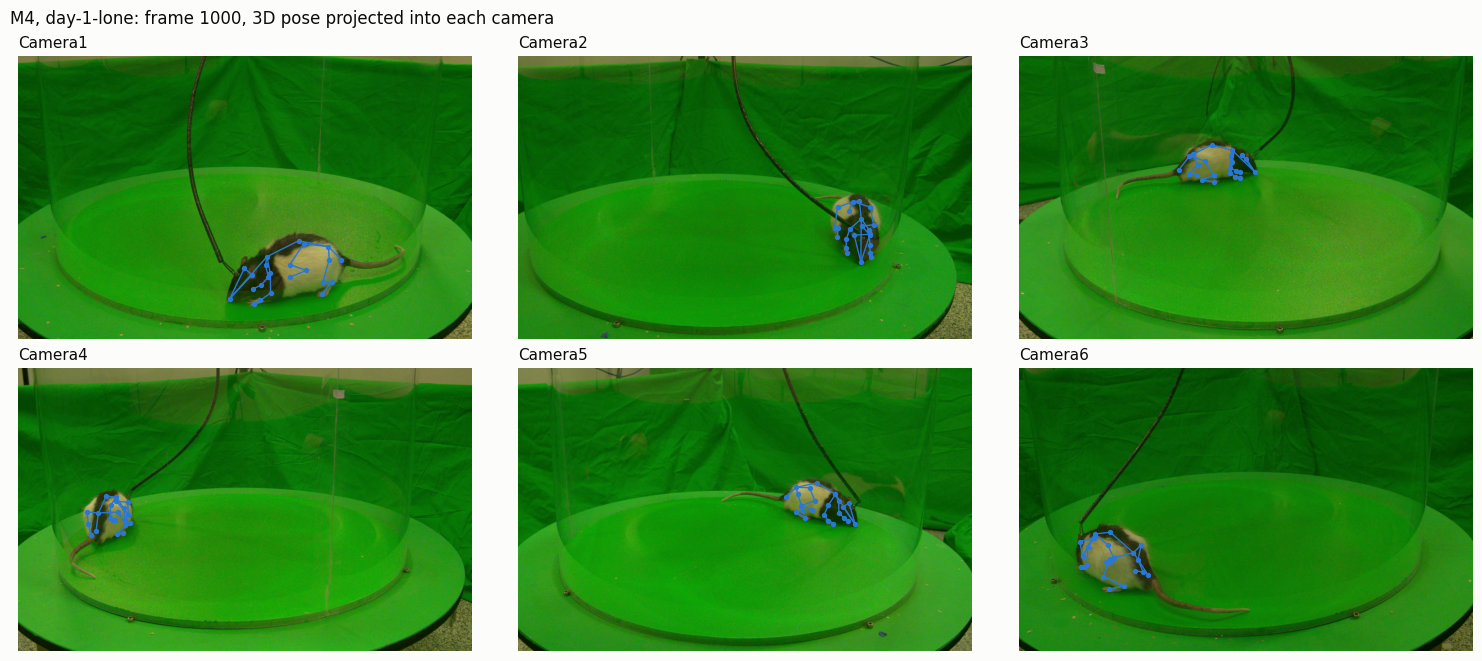

In [12]:
if not missing:
    fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), constrained_layout=True)
    for ax, camera in zip(axes.flat, sorted(video_paths)):
        frame = read_frame(video_paths[camera], frame_idx)
        ax.imshow(frame)
        draw_pose(ax, project_points(lone_xyz[frame_idx], calibrations[camera]), RAT_COLORS["subject"])
        ax.set_title(camera)
        ax.axis("off")
    fig.suptitle(f"{lone_label}: frame {frame_idx}, 3D pose projected into each camera", x=0.01, ha="left", color=INK)
    plt.show()

### A social session: subject and partner

The social session of the same rat has two pose containers. Both share the cameras, videos and calibrations, so the same projection works for either rat.

**When is the partner in the arena?** The mean distance between the two rats' matching keypoints shows when both animals are tracked. In M4 day-1-social it drops to about zero for long stretches at the start and the end. In video frames from those stretches only one rat is visible, so there sDANNCE reports the subject twice. This is in the lab's sDANNCE output, not introduced by the conversion or by Spyglass. Whether the partner is always added partway through, and when, is an open question with the lab (see the conversion notes). Until it is answered, analyses of the partner should use only frames where the two tracks are apart; here that means more than 20 mm.

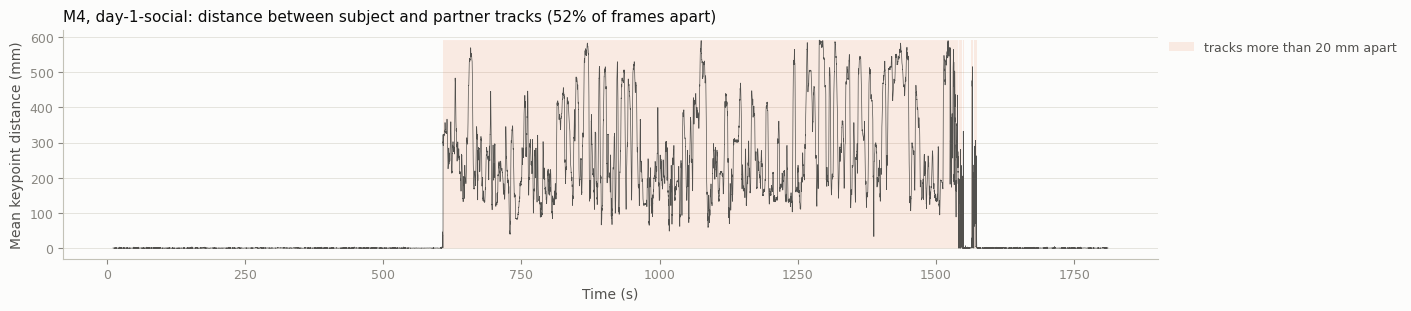

In [13]:
SEPARATION_MM = 20.0

social = sessions[
    (sessions["task_name"] == "social") & (sessions["subject_id"] == lone["subject_id"])
].iloc[0]
social_label = f"{social['subject_id']}, {social['session_id']}"
social_xyz = {
    RAT_OF[name]: keypoint_array(
        fetch_pose({"nwb_file_name": social["nwb_file_name"], "pose_estimation_name": name}), nodes
    )
    for name in EXPECTED_CONTAINERS["social"]
}
social_t = fetch_pose(
    {"nwb_file_name": social["nwb_file_name"], "pose_estimation_name": "PoseEstimationDANNCE"}
)[nodes[0]].index.to_numpy()


def separation(subject_xyz, partner_xyz):
    # Mean distance (mm) between matching keypoints of the two rats, per frame
    return np.linalg.norm(subject_xyz - partner_xyz, axis=2).mean(axis=1)


distance = separation(social_xyz["subject"], social_xyz["partner"])
apart = distance > SEPARATION_MM

fig, ax = plt.subplots(figsize=(14, 3), constrained_layout=True)
ax.plot(social_t, distance, color=INK_2, linewidth=0.5, rasterized=True)
ax.fill_between(social_t, 0, distance.max(), where=apart, color=RAT_COLORS["partner"], alpha=0.12, linewidth=0,
                label=f"tracks more than {SEPARATION_MM:.0f} mm apart")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Mean keypoint distance (mm)")
ax.set_title(f"{social_label}: distance between subject and partner tracks ({apart.mean():.0%} of frames apart)")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.show()

The frame below is from the middle of the session, where the tracks are apart. Both skeletons are projected into one camera.

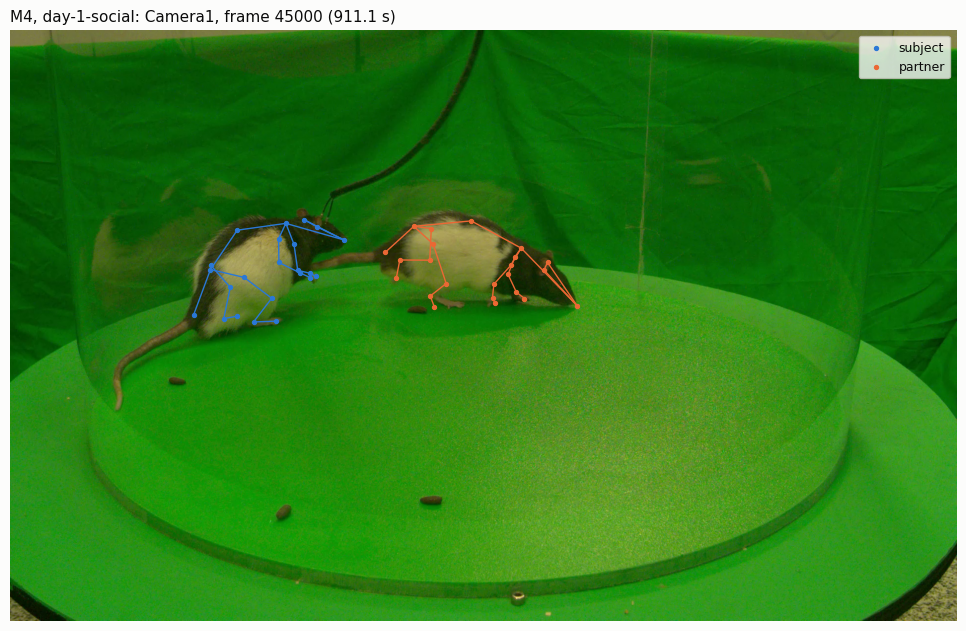

In [14]:
social_frame_idx = 45000
assert apart[social_frame_idx], "pick a frame where the two tracks are apart"

social_key = {"nwb_file_name": social["nwb_file_name"], "pose_estimation_name": "PoseEstimationDANNCE"}
social_videos = {cam: resolve_video(p) for cam, p in ImportedMultiCameraPose().fetch_video_paths(social_key).items()}
social_calibrations = ImportedMultiCameraPose().fetch_calibrations(social_key)
camera = "Camera1"

if social_videos[camera].exists():
    fig, ax = plt.subplots(figsize=(10, 6.2), constrained_layout=True)
    ax.imshow(read_frame(social_videos[camera], social_frame_idx))
    for rat, xyz in social_xyz.items():
        draw_pose(ax, project_points(xyz[social_frame_idx], social_calibrations[camera]), RAT_COLORS[rat], rat)
    ax.set_title(f"{social_label}: {camera}, frame {social_frame_idx} ({social_t[social_frame_idx]:.1f} s)")
    ax.legend(loc="upper right", frameon=True, facecolor=SURFACE, edgecolor=AXIS, labelcolor=INK)
    ax.axis("off")
    plt.show()
else:
    print(f"Video not found: {social_videos[camera]} (check DATA_SHARE)")

### Every session side by side

The same steps, applied to every session in the database. For each session the table reports:

- the subject's median speed (SpineMiddle, 1 s smoothing),
- in social sessions, the fraction of frames where the subject and partner tracks are more than 20 mm apart,
- and the subject's median speed in just those frames.

The speeds illustrate how to work with the data; they are not the lab's analysis. In social sessions the whole-session speed includes the stretches where the partner is not tracked.

Everything is looked up by session name. When new sessions are inserted, rerunning the notebook adds them to the checks, the table and the figure with no code changes.

In [15]:
def summarize_session(session):
    keys = {
        RAT_OF[name]: {"nwb_file_name": session.nwb_file_name, "pose_estimation_name": name}
        for name in EXPECTED_CONTAINERS[session.task_name]
    }
    subject_pose = fetch_pose(keys["subject"])
    speed = body_speed(subject_pose)
    row = {
        "subject_id": session.subject_id,
        "session_id": session.session_id,
        "task_name": session.task_name,
        "minutes": (subject_pose.index[-1] - subject_pose.index[0]) / 60,
        "median_speed_mm_s": speed.median(),
        "fraction_apart": np.nan,
        "median_speed_apart_mm_s": np.nan,
    }
    if "partner" in keys:
        apart = separation(
            keypoint_array(subject_pose, nodes), keypoint_array(fetch_pose(keys["partner"]), nodes)
        ) > SEPARATION_MM
        row["fraction_apart"] = apart.mean()
        # speed[i] is the step from frame i to i + 1
        row["median_speed_apart_mm_s"] = speed[apart[1:]].median()
    return row


summary = pd.DataFrame([summarize_session(s) for s in sessions.itertuples()])
summary.round(2)

,subject_id,session_id,task_name,minutes,median_speed_mm_s,fraction_apart,median_speed_apart_mm_s
0,M4,day-1-lone,lone,30.0,25.18,NaN,NaN
1,M4,day-1-social,social,30.0,58.83,0.52,87.65
2,M4,day-2-lone,lone,30.0,22.53,NaN,NaN
3,M4,day-2-social,social,35.0,48.93,0.44,74.54
4,M5,day-1-lone,lone,30.0,43.58,NaN,NaN
5,M5,day-1-social,social,35.0,55.73,0.45,84.88
6,M5,day-2-lone,lone,30.0,40.17,NaN,NaN
7,M5,day-2-social,social,35.0,71.24,0.45,103.10
8,M7,day-1-lone,lone,30.0,29.79,NaN,NaN
9,M7,day-1-social,social,35.0,46.41,0.45,87.15


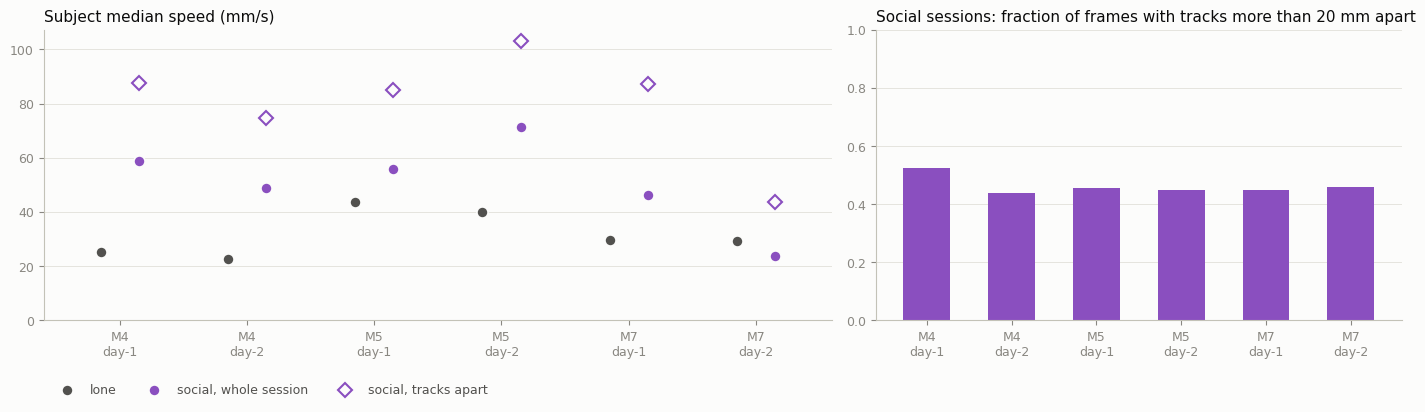

In [16]:
# One x position per rat and day; lone and social side by side
summary["day"] = summary["session_id"].str.extract(r"(day-\d+)", expand=False)
groups = summary[["subject_id", "day"]].drop_duplicates().sort_values(["subject_id", "day"]).reset_index(drop=True)
x_of = {(row.subject_id, row.day): i for i, row in enumerate(groups.itertuples())}
summary["x"] = [x_of[(s, d)] for s, d in zip(summary["subject_id"], summary["day"])]
lone_rows, social_rows = summary[summary["task_name"] == "lone"], summary[summary["task_name"] == "social"]
CONDITION_COLORS = {"lone": INK_2, "social": "#8a4fbf"}
marker_style = dict(linestyle="none", markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.2)

fig, (ax_speed, ax_apart) = plt.subplots(
    1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 2]}, constrained_layout=True
)
ax_speed.plot(lone_rows["x"] - 0.15, lone_rows["median_speed_mm_s"], marker="o",
              markerfacecolor=CONDITION_COLORS["lone"], label="lone", **marker_style)
ax_speed.plot(social_rows["x"] + 0.15, social_rows["median_speed_mm_s"], marker="o",
              markerfacecolor=CONDITION_COLORS["social"], label="social, whole session", **marker_style)
ax_speed.plot(social_rows["x"] + 0.15, social_rows["median_speed_apart_mm_s"], marker="D",
              markerfacecolor=SURFACE, markeredgecolor=CONDITION_COLORS["social"], linestyle="none",
              markersize=7, markeredgewidth=1.5, label="social, tracks apart")
ax_speed.set_title("Subject median speed (mm/s)")
ax_speed.set_ylim(bottom=0)
ax_speed.legend(loc="upper left", bbox_to_anchor=(0.0, -0.18), ncol=3)

ax_apart.bar(social_rows["x"], social_rows["fraction_apart"], color=CONDITION_COLORS["social"], width=0.55)
ax_apart.set_title(f"Social sessions: fraction of frames with tracks more than {SEPARATION_MM:.0f} mm apart")
ax_apart.set_ylim(0, 1)

for ax in (ax_speed, ax_apart):
    ax.set_xticks(range(len(groups)), groups["subject_id"] + "\n" + groups["day"])
    ax.set_xlim(-0.6, len(groups) - 0.4)
plt.show()

## Summary

- **Queried from the database alone:** which pose containers each session has (the subject's, and the partner's in social sessions), their 23 keypoints, which cameras are calibrated, the video per camera, the task condition and the pose's valid times.
- **Fetched through Spyglass:** the 3D keypoints, the skeleton, the camera calibrations and the video paths, with no NWB file paths in this notebook.
- **Worked with them:** drew the skeleton in 3D and on all six camera views, followed the rat's movement, found where the subject and partner tracks coincide in a social session, and compared every session in one table.

The partner track coincides with the subject's whenever the partner is not tracked as a separate animal. Until the lab confirms when the partner is in the arena, the distance between the two tracks is the way to tell.